# 02 · Model experiments

Task: predict a session's **average heart rate** from the workout's external load and what was known about the athlete before it. Full code: `src/athleteiq/model.py`, `pipeline.py`.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from athleteiq.config import data_dir
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
D = data_dir(); print('data:', D.relative_to(D.parents[1]))
from athleteiq.features import FEATURES, PRETTY
m = json.load(open('../models/metrics.json'))

data: data/processed


## Splits (no leakage)
- **train / val / test**: the first 70 % / next 15 % / most recent 15 % of each athlete's sessions.
- **holdout**: 15 % of athletes never seen in training.
- **calib**: 10 % more unseen athletes, used only to calibrate intervals.

In [2]:
pd.Series(m['splits']).rename('sessions')

train      22102
holdout     4865
val         4563
test        4333
calib       4323
Name: sessions, dtype: int64

## Baselines first, then ML

In [3]:
rows = []
for sp in ['val','test','holdout']:
    for k, v in m['by_split'][sp].items():
        if isinstance(v, dict): rows.append({'split': sp, 'model': k, **{x: round(v[x], 3) for x in ['mae','rmse','r2','within_5bpm']}})
pd.DataFrame(rows).pivot(index='model', columns='split', values='mae').loc[['global_mean','athlete_last5','personal_speed_fit','ridge','lgbm','lgbm_personal']]

split,holdout,test,val
model,,,
global_mean,9.310,10.371,9.859
athlete_last5,7.531,7.208,6.820
personal_speed_fit,6.131,5.769,5.411
ridge,5.436,5.052,4.931
lgbm,5.233,4.853,4.679
lgbm_personal,5.231,4.751,4.611


In [4]:
t = m['by_split']['test']
print(f"LightGBM+personalisation vs athlete last-5 baseline: {1 - t['lgbm_personal']['mae']/t['athlete_last5']['mae']:.0%} lower MAE")
print(f"LightGBM+personalisation vs personal speed-HR fit: {1 - t['lgbm_personal']['mae']/t['personal_speed_fit']['mae']:.0%} lower MAE")

LightGBM+personalisation vs athlete last-5 baseline: 34% lower MAE
LightGBM+personalisation vs personal speed-HR fit: 18% lower MAE


## Online personalisation
After each evaluated session the true HR is known, so the model can learn an athlete-specific offset: shrunk mean of past errors, `sum(residuals)/(n+k)`. `k` was chosen on validation.

In [5]:
print('k chosen:', m['best_shrinkage_k']); pd.Series(m['val_mae_by_k']).rename('val MAE')

k chosen: 10


1     4.746168
2     4.678751
5     4.623352
10    4.611476
20    4.620628
50    4.641282
Name: val MAE, dtype: float64

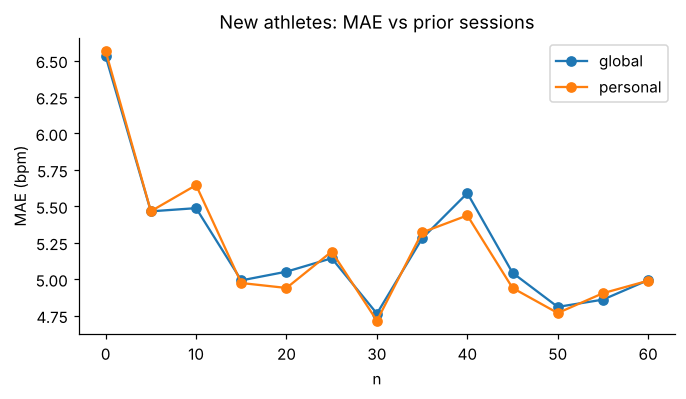

In [6]:
lc = pd.DataFrame(m['holdout_learning_curve'])
ax = lc.plot(x='n', y=['global','personal'], marker='o', figsize=(7,3.5), title='New athletes: MAE vs prior sessions')
ax.set_ylabel('MAE (bpm)');

Honest result: personalisation helps on known athletes' future sessions (≈0.1 bpm) but gives no measurable gain on brand-new athletes - the history features already capture most of what the offset would learn.

## Uncertainty: conformal prediction intervals
Plain split conformal (calibrated on validation sessions) under-covers brand-new athletes, because validation sessions all have long histories. Mondrian conformal calibrates a separate width per history band using the calibration athletes.

In [7]:
print(json.dumps(m['conformal'], indent=1))
pd.DataFrame(m['error_analysis']['holdout']['history_bucket'])

{
 "alpha": 0.1,
 "plain_half_width_bpm": 9.791786023201695,
 "mondrian_half_width_bpm": {
  "0-4": 13.225336817938015,
  "5-19": 10.426441580922528,
  "20+": 9.645869154694878
 }
}


,history_bucket,n,mae,coverage,coverage_plain
0,0-4,425,6.564,0.887,0.774
1,5-19,1130,5.380,0.878,0.860
2,20-49,1337,5.078,0.861,0.868
3,50+,1973,4.963,0.874,0.877


In [8]:
for sp in ['test','holdout']: print(sp, 'coverage plain:', round(m['by_split'][sp]['interval_coverage_plain'],3), '| mondrian:', round(m['by_split'][sp]['interval_coverage'],3))

test coverage plain: 0.895 | mondrian: 0.892
holdout coverage plain: 0.861 | mondrian: 0.873


## Error analysis

In [9]:
pd.DataFrame(m['error_analysis']['test']['label_workout_type'])

,label_workout_type,n,mae,coverage,coverage_plain
0,INTENSIVE,223,7.981,0.682,0.691
1,RECOVERY,1824,4.789,0.897,0.901
2,STEADY,2286,4.406,0.908,0.911


Intensive sessions are hardest (MAE ≈ 8 bpm) and under-covered: the workout's speed alone does not reveal how hard an interval session felt, and those sessions are rare (≈5 %).

In [10]:
pd.DataFrame(m['error_analysis']['test']['duration_bucket'])

,duration_bucket,n,mae,coverage,coverage_plain
0,<30,306,5.418,0.866,0.869
1,30-60,1830,4.864,0.887,0.890
2,60-90,1388,4.597,0.904,0.910
3,90+,809,4.509,0.892,0.894


## Explainability (SHAP)

In [11]:
gi = pd.DataFrame(m['global_importance'])
gi.head(12)[['label','mean_abs_shap_bpm']]

,label,mean_abs_shap_bpm
0,Personal HR expected at this speed,4.899
1,Avg speed (km/h),2.425
2,"Avg HR, last 5 sessions",1.895
3,"Efficiency, last 5 sessions",1.766
4,"Avg speed, last 5 sessions",0.690
5,Day of week,0.574
6,Distance (km),0.556
7,Speed variability,0.468
8,Hour of day,0.398
9,Elevation gain (m),0.382


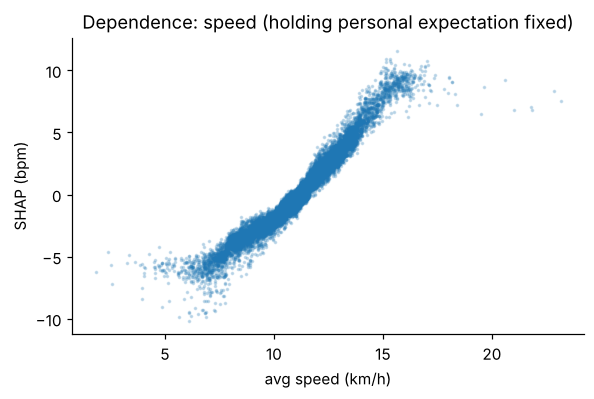

In [12]:
sh = pd.read_parquet(D / 'shap_values.parquet'); s = pd.read_parquet(D / 'sessions.parquet').set_index('workout_id')
x = s.loc[sh.workout_id, 'avg_speed_kmh'].to_numpy()
fig, ax = plt.subplots(figsize=(6,3.5)); ax.scatter(x, sh.avg_speed_kmh, s=2, alpha=.2)
ax.set(xlabel='avg speed (km/h)', ylabel='SHAP (bpm)', title='Dependence: speed (holding personal expectation fixed)');

The single most useful input is the athlete's **own** speed–HR relationship from earlier sessions. Speed then adjusts it. These are model associations, not causal physiology.